Very often data are stored in tabular format:
- Each line corresponds to an observation (individual, sample, ... ).
- Each column correspond to a measured variable (height, sex, gene expression, ... )

In python, the most popular module to read and manipulate tabulated data is certainly `pandas`, a "high-level" module designed for statistics/exploratory data analysis. A great strength of pandas is its DataFrame object, but first we will focus on pandas Series. Let's see how they look:

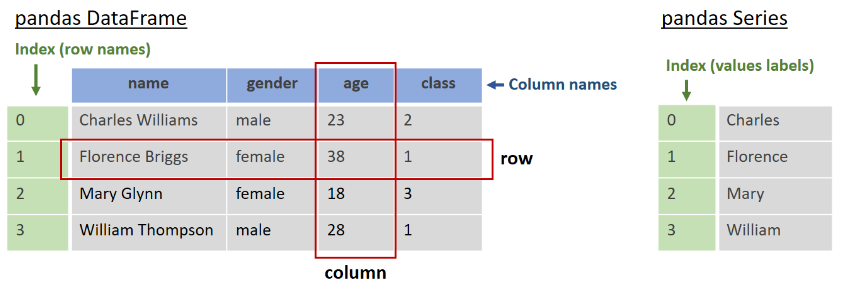

In [1]:
import os
import numpy as np
import pandas as pd

In [2]:
os.chdir("../data")

# Data Structures - Series

In [ ]:
pd.Series?

## List as a constructor

Pandas Series can be constructed by passing a list of values to its constructor. By default, each item will receive an index label from 0 to N-1, where N is the total number of values in the Series. Specific index can be forwarded, too, by using parameter `index` while "constructing".

In [3]:
s1 = pd.Series([7, 'Heisenberg', 3.14, -1789710578, 'Happy Eating!'])  

In [4]:
s1

0                7
1       Heisenberg
2             3.14
3      -1789710578
4    Happy Eating!
dtype: object

In [5]:
s1.shape # just like with NumPy array, shape will return the shape of the object

(5,)

In [6]:
s1.values # to access only Series values without index

array([7, 'Heisenberg', 3.14, -1789710578, 'Happy Eating!'], dtype=object)

Notice that values of pandas Series object are in the NumPy array.

In [7]:
s1.index # to access only Series index

RangeIndex(start=0, stop=5, step=1)

We can access Series elements similar to accessing elements of NumPy arrays and lists, but pandas has its own selection methods the so called `iloc` and `loc`. They provide you a way of indexing/slicing based on location (index), `iloc` for integer-based selection and `loc` for selection based on specific index.

In [8]:
s1[1] # indexing like with NumPy arrays

'Heisenberg'

In [9]:
s1.iloc[1] # selection by position (integer-based location)

'Heisenberg'

In [10]:
s1[1:3] # slicing like with NumPy arrays

1    Heisenberg
2          3.14
dtype: object

In [11]:
s1.iloc[1:3] # slicing by position (integer-based location)

1    Heisenberg
2          3.14
dtype: object

<div class="alert alert-block alert-warning">
<b>Example: </b>Create a pandas Series containing temperature measurements for different days of the week. Get:
    
    1. The temperature on Tuesday
    2. The temperature on Tuesday and Thursday.
    3. The temperature from Tuesday to Thursday.
</div>

In [12]:
# Temperature measurements with user-defined index
temperatures = pd.Series([18.5, 22.0, 16.5, 25.0, 20.0], index=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"])
print(temperatures)

Monday       18.5
Tuesday      22.0
Wednesday    16.5
Thursday     25.0
Friday       20.0
dtype: float64


In [14]:
temperatures.index # check Series index 

Index(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday'], dtype='str')

In [13]:
# Indexing: get the temperature on Tuesday
print(temperatures["Tuesday"])

# Indexing: get the temperature on Tuesday and Thursday
print(temperatures[["Tuesday", "Thursday"]])

# Slicing: get temperatures from Tuesday to Thursday
print(temperatures["Tuesday":"Thursday"])

22.0
Tuesday     22.0
Thursday    25.0
dtype: float64
Tuesday      22.0
Wednesday    16.5
Thursday     25.0
dtype: float64


<div class="alert alert-block alert-success">
<b>Task: </b>Create a pandas Series containing the daily number of visitors to a website for five days. Use the days of the week as the index, retrieve the number of visitors on a specific day, and slice the Series to display the values for several consecutive days.
</div>

In [ ]:
#solution

OR

## Dictionary as a constructor 

Pandas Series object accepts a dictionary as a constructor (not only lists). In that case, the constructor converts the dictionary using the keys of the dictionary as its index:

<div class="alert alert-block alert-warning">
<b>Example: </b>A company wants to compare the number of customers across several US cities (Chicago, New York, Portland, San Francisco, Austin, Boston). The dictionary d contains the number of customers in each city, with None indicating missing data for Boston.

Create a pandas Series from the dictionary. Display the Series, access the number of customers in a specific city, and use slicing or indexing to select data for multiple cities.
</div>

In [15]:
d = {'Chicago': 1000, 'New York': 1300, 'Portland': 900, 'San Francisco': 1100, 'Austin': 450, 'Boston': None}
cities = pd.Series(d)

In [16]:
cities

Chicago          1000.0
New York         1300.0
Portland          900.0
San Francisco    1100.0
Austin            450.0
Boston              NaN
dtype: float64

For example, we can select the following cities:

In [17]:
cities_selected = cities[['Chicago', 'Portland', 'San Francisco']]
cities_selected

Chicago          1000.0
Portland          900.0
San Francisco    1100.0
dtype: float64

## Other pandas Series properties

Identify which city has missing data.

In [18]:
cities.isnull() #Check if there is a null or missing value (NaN) in a Series

Chicago          False
New York         False
Portland         False
San Francisco    False
Austin           False
Boston            True
dtype: bool

For selecting only rows without NaN values, use negation operator `~` before `pd.Series.isnull()`:

In [19]:
cities[~cities.isnull()]

Chicago          1000.0
New York         1300.0
Portland          900.0
San Francisco    1100.0
Austin            450.0
dtype: float64

Series value for specific index can be directly changed:

In [20]:
cities['Chicago'] = 1400    # changing value based on the index
print('New value for Chicago:', cities['Chicago'])

New value for Chicago: 1400.0


Pandas Series can also be subset based on a condition(s) (similar to `numpy.where`):

In [21]:
cities_less_1000 = cities[cities < 1000] # Only rows with a value less than 1000 are selected.
cities_less_1000 

Portland    900.0
Austin      450.0
dtype: float64

Operator `in` works here too:

In [22]:
'Seattle' in cities, 'San Francisco' in cities # Boolean expressions

(False, True)

Compute Boolean array indicating whether each Series value is contained in the passed sequence of values:

In [23]:
cities.isin([1000, 900])

Chicago          False
New York         False
Portland          True
San Francisco    False
Austin           False
Boston           False
dtype: bool

Mathematical operations are performed row-wise.

In [24]:
cities / 3 # arithmetic operations

Chicago          466.666667
New York         433.333333
Portland         300.000000
San Francisco    366.666667
Austin           150.000000
Boston                  NaN
dtype: float64

In [25]:
np.square(cities) # numpy operations

Chicago          1960000.0
New York         1690000.0
Portland          810000.0
San Francisco    1210000.0
Austin            202500.0
Boston                 NaN
dtype: float64

If two pandas Series are added, then only index-matching rows will be added and others will be NaN. See next example.

<div class="alert alert-block alert-warning">
<b>Example: </b>Suppose we have another Series with the number of customers per city, but with additional cities compared to the previous example.
</div>

In [26]:
d2 = {'Chicago': 500, 'New York': 2000, 'San Francisco': 1100, 'Los Angeles': 5000}
cities2 = pd.Series(d2)
cities2

Chicago           500
New York         2000
San Francisco    1100
Los Angeles      5000
dtype: int64

In [27]:
cities+cities2 # automatically aligns differently indexed data in arithmetic operations

Austin              NaN
Boston              NaN
Chicago          1900.0
Los Angeles         NaN
New York         3300.0
Portland            NaN
San Francisco    2200.0
dtype: float64

<div class="alert alert-block alert-success">
<b>Task: </b>Discuss the previous operation on pandas Series.
</div>

# Data Structures - DataFrame

In [ ]:
pd.DataFrame?

Pandas DataFrames are the most similar to tables. Beside indices, like pandas Series, they have columns. Each DataFrame column is a pandas Series. DataFrame can be constructed from a dictionary, which keys will become column names and values (lists) contain row values for specific column.

If the dictionary values are not lists, but specific value, than:

*Solution 1* - add index

In [28]:
dd = pd.DataFrame({'A':1,'B':2}, index=[0])
dd

,A,B
0,1,2


*Solution 2* - place dictionary in a list

In [29]:
my_dict = {'A':1,'B':2}
dd = pd.DataFrame([my_dict])
dd

,A,B
0,1,2


Let's create our first "big" DataFrame from a dictionary:

In [30]:
# Create an example dataframe about a fictional army
raw_data = {'regiment': ['Nighthawks', 'Nighthawks', 'Nighthawks', 'Nighthawks', 'Dragoons', 'Dragoons', 'Dragoons', 'Dragoons', 'Scouts', 'Scouts', 'Scouts', 'Scouts'],
            'company': ['1st', '1st', '2nd', '2nd', '1st', '1st', '2nd', '2nd','1st', '1st', '2nd', '2nd'],
            'deaths': [523, 52, 25, 616, 43, 234, 523, 62, 62, 73, 37, 35],
            'battles': [5, 42, 2, 2, 4, 7, 8, 3, 4, 7, 8, 9],
            'size': [1045, 957, 1099, 1400, 1592, 1006, 987, 849, 973, 1005, 1099, 1523],
            'veterans': [1, 5, 62, 26, 73, 37, 949, 48, 48, 435, 63, 345],
            'readiness': [1, 2, 3, 3, 2, 1, 2, 3, 2, 1, 2, 3],
            'armored': [1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1],
            'deserters': [4, 24, 31, 2, 3, 4, 24, 31, 2, 3, 2, 3],
            'origin': ['Arizona', 'California', 'Texas', 'Florida', 'Maine', 'Iowa', 'Alaska', 'Washington', 'Oregon', 'Wyoming', 'Louisana', 'Georgia']}

df = pd.DataFrame(raw_data, columns = ['regiment', 'company', 'deaths', 'battles', 'size', 'veterans', 'readiness', 'armored', 'deserters', 'origin'])

df.head()

,regiment,company,deaths,battles,size,veterans,readiness,armored,deserters,origin
0,Nighthawks,1st,523,5,1045,1,1,1,4,Arizona
1,Nighthawks,1st,52,42,957,5,2,0,24,California
2,Nighthawks,2nd,25,2,1099,62,3,1,31,Texas
3,Nighthawks,2nd,616,2,1400,26,3,1,2,Florida
4,Dragoons,1st,43,4,1592,73,2,0,3,Maine


DataFrame has also properties like `shape`, `values`, `index`, and additionally `columns`. Each column has its data type that can be checked with property `dtypes`:

In [31]:
df.dtypes

regiment       str
company        str
deaths       int64
battles      int64
size         int64
veterans     int64
readiness    int64
armored      int64
deserters    int64
origin         str
dtype: object

If your DataFrame is really big, show only a few rows with:

In [32]:
df.head()

,regiment,company,deaths,battles,size,veterans,readiness,armored,deserters,origin
0,Nighthawks,1st,523,5,1045,1,1,1,4,Arizona
1,Nighthawks,1st,52,42,957,5,2,0,24,California
2,Nighthawks,2nd,25,2,1099,62,3,1,31,Texas
3,Nighthawks,2nd,616,2,1400,26,3,1,2,Florida
4,Dragoons,1st,43,4,1592,73,2,0,3,Maine


By default `df.head()` will print first 5 rows, but by forwarding *n* in the method call, it would print *n* rows

<div class="alert alert-block alert-info">
<b>Tip: </b>Differentiate properties and methods: Properties do not have round-brackets <code>()</code> after them, while methods (functions) are always written with <code>()</code>. For example, <code>df.shape</code> (property) and <code>df.head()</code> (method).
</div>

After DataFrame creation, you can set certain column as index:

In [33]:
df = df.set_index('origin')
df.head()

,regiment,company,deaths,battles,size,veterans,readiness,armored,deserters
origin,,,,,,,,,
Arizona,Nighthawks,1st,523,5,1045,1,1,1,4
California,Nighthawks,1st,52,42,957,5,2,0,24
Texas,Nighthawks,2nd,25,2,1099,62,3,1,31
Florida,Nighthawks,2nd,616,2,1400,26,3,1,2
Maine,Dragoons,1st,43,4,1592,73,2,0,3


## Selection

Selection and indexing is performed similar to pandas Series selection and indexing.

For selecting columns, pass column name or list of columns:

In [34]:
df['size'] # Select a column

origin
Arizona       1045
California     957
Texas         1099
Florida       1400
Maine         1592
Iowa          1006
Alaska         987
Washington     849
Oregon         973
Wyoming       1005
Louisana      1099
Georgia       1523
Name: size, dtype: int64

In [35]:
df[['size', 'veterans']] # Select multiple columns

,size,veterans
origin,,
Arizona,1045,1
California,957,5
Texas,1099,62
Florida,1400,26
Maine,1592,73
Iowa,1006,37
Alaska,987,949
Washington,849,48
Oregon,973,48


<div class="alert alert-block alert-warning">
<b>Example: </b>Practice selecting rows, columns, and individual values using pandas. Complete the following tasks:

1. Select all rows up to and including a specified state using its index label.
2. Select all rows up to, but not including, a specified row using its integer position.
3. Select all rows and only the first two columns.
4. Select the value in the third column of the row indexed by "Arizona" using label-based indexing.
5. Select the value in the third column of the row indexed by "Arizona" using integer-position-based indexing.
</div>

In [36]:
df.loc[:'Alaska'] # Select all rows upto specified index label (by user-defined index henc loc)

,regiment,company,deaths,battles,size,veterans,readiness,armored,deserters
origin,,,,,,,,,
Arizona,Nighthawks,1st,523,5,1045,1,1,1,4
California,Nighthawks,1st,52,42,957,5,2,0,24
Texas,Nighthawks,2nd,25,2,1099,62,3,1,31
Florida,Nighthawks,2nd,616,2,1400,26,3,1,2
Maine,Dragoons,1st,43,4,1592,73,2,0,3
Iowa,Dragoons,1st,234,7,1006,37,1,1,4
Alaska,Dragoons,2nd,523,8,987,949,2,0,24


In [37]:
df.iloc[:2] # Select every row up to defined index of row (by integer location hence iloc)

,regiment,company,deaths,battles,size,veterans,readiness,armored,deserters
origin,,,,,,,,,
Arizona,Nighthawks,1st,523,5,1045,1,1,1,4
California,Nighthawks,1st,52,42,957,5,2,0,24


In [ ]:
df.iloc[:,:2] # Select all rows and the first 2 columns

In [ ]:
df.loc['Arizona', 'deaths']  # Select the third cell in the row named Arizona

In [ ]:
df.iloc[0, 2] # Select the third cell in the row named Arizona

<div class="alert alert-block alert-info">
<b>Tip: </b>Notice that for pandas Series both iloc/loc and numpy-like indexing/slicing can be used, but for DataFrame one is used for rows and other for column indexing/slicing.
</div>

# Reading/writing the data in pandas

Since we are working with tabular data (arbitrary big), it is convenient to import data from a file. Usually, the input formats are: Comma Separated Values File (.csv), Tab Separated Values File (.tsv), Microsoft Excel Worksheet (.xlsx) and others. Most formats can be imported using `pandas.read_csv()` method, which by default receives CSV files, but by changing the default delimiter (in case of TSV it is `'\t'`), it can be accounted for other formats too.

Check the documentation for other parameters in `pandas.read_csv()`.

In [ ]:
pd.read_csv?

<div class="alert alert-block alert-warning">
    <b>Example: </b>Import file <i>database_biosense.csv</i> into a pandas DataFrame.
</div>

In [ ]:
data_from_csv = pd.read_csv('database_biosense.csv') # by default file is imported from the data folder
data_from_csv.head()

In [ ]:
data_from_csv.dtypes

<div class="alert alert-block alert-warning">
    <b>Example: </b>Save <code>cities</code> DataFrame into CSV file.
</div>

In [ ]:
cities.to_csv('cities.csv') # Writing data to csv file, check data folder for file cities.csv

Similar to `read_csv()` and `to_csv()`, for `.xlsx` format reading/writing use `read_excel()` and `to_excel()`.

<div class="alert alert-block alert-info">
    <b>Tip: </b>Notice that <code>.xlsx </code> format can have sheets and when importing you can indicate which sheet you want to import. 
    For more advanced use of <code>.xlsx </code> format read <a href="https://xlsxwriter.readthedocs.io/working_with_pandas.html">tutorial</a> or use libraries like <a href="https://openpyxl.readthedocs.io/en/stable/">openpyxl</a>.
</div>

<div class="alert alert-block alert-success">
    <b>Task: </b> Create pandas DataFrame and save it to TSV format. Read data from the TSV file.
</div>

In [ ]:
# solution

# Basic description - common summary statistics

When doing exploratory analysis of a dataset, it is often useful get some basic statistics on a per-column basis (since rows will typically represent the samples and columns the explanatory variables).

Pandas has a number of methods that can be applied both on an entire DataFrame or on individual columns (Series):
- `describe()` : prints summary statistics for all numeric columns (count, mean, min, max, std, quantiles).
- `count()`: returns the count of values (in each column, if applied to a DataFrame), that are not NaN.
- `unique()`: returns NumPy array of unique values (apply on Series).
- `value_counts()`: returns the count of each value. Useful for discrete variables (e.g. factors).
- `min()`, `max()`, `mean()`, `std()`, `quantile()`, `sum()`: returns the min, max, mean, etc.

When applied to a DataFrame, these methods compute values for all columns, skipping columns for which they cannot be applied (e.g. standard deviation can only be computed for numeric columns). They can also be computed by row by adding the `axis=1` argument. 

<div class="alert alert-block alert-success">
    <b>Task: </b> In <code>titanic.csv</code> file:
    <ol>
        <li>Count the unique sex values.</li>
        <li>Find maximum and minimum age of the passengers that survived.</li>
        <li>Calculate the median fare separately for male and female passengers. Do the median fares differ between the two groups?</li>
    </ol>
</div>

In [ ]:
#solution

# Missing values manipulation

Imagine that you are working as a data scientist for a company X. Before analyzing the data, you notice that some values are missing or incomplete. What should you do with these missing values? Should you remove the rows containing missing data, replace the missing values with estimates, or leave them as they are?

The answer depends on the type of data, the reason the values are missing, and the goals of your analysis. Removing too many rows may result in losing valuable information, while replacing missing values without careful consideration may introduce bias into the results.

## Removing missing values

We have already mentioned that missing values can be checked with `isnull()` method. But if you want to remove them, use `dropna()`:

In [ ]:
s = pd.Series(['aardvark', 'artichoke', np.nan, 'avocado'])

In [ ]:
s.dropna()

By applying `dropna()` on DataFrame, only rows with no NaN value would be retained:

In [38]:
df = pd.DataFrame([[1., 6.5, 3.], [1., None, None],[None, None, None], [None, 6.5, 3.]])
df

In [ ]:
df1 = df.dropna()  # dropna() by default drops any row containing a missing value
df1

If it is not the desired behaviour, use parameter `how`, which takes strings `'all'`, meaning drop rows that contain all NaN values or `'any'`, which is the default behaviour.

In [41]:
df2 = df.dropna(how='all')   # how='all' will only drop rows that are all None
df2

,0,1,2
0,1.0,6.5,3.0
1,1.0,NaN,NaN
3,NaN,6.5,3.0


For more precise method, use parameter `thresh` to pass specific number of occurences of non-NaN values.

In [42]:
df = pd.DataFrame(np.random.randn(7, 3))
df.loc[:4, 1] = np.nan; df.loc[:2, 2] = np.nan
df

,0,1,2
0,-0.474470,NaN,NaN
1,-0.158011,NaN,NaN
2,1.369915,NaN,NaN
3,0.257681,NaN,0.617953
4,-0.482914,NaN,0.547272
5,1.005959,1.761995,-2.037255
6,-0.061349,-0.780568,0.789250


In [43]:
df.dropna(thresh=2)

,0,1,2
3,0.257681,NaN,0.617953
4,-0.482914,NaN,0.547272
5,1.005959,1.761995,-2.037255
6,-0.061349,-0.780568,0.789250


## Filling missing values

To fill missing values, use `fillna()` method.

In [ ]:
df.fillna(0) # Replacing missing values with constant value

In [ ]:
df.fillna({1: 0.5, 2: -1}) # define specific fill value for each column (dictionary key)

In [ ]:
df.fillna(0, inplace=True)   # fillna returns a new object, but with inplace=True we modify the existing object in place
df

<div class="alert alert-block alert-success">
<b>Task: </b>
    <ol>
        <li>Load data <code>breast-cancer-wisconsin.data.txt</code>.</li>
        <li>Check dtypes of data frame.</li>
        <li>Check if there are missing values.</li>
        <li>Replace missing values with mean value in the column.</li>
    </ol>
</div>


In [ ]:
# Hint for start
cancer_header = ['Sample code number', 'Clump Thickness', 'Uniformity of Cell Size', 'Uniformity of Cell Shape', 'Marginal Adhesion', 'Single Epithelial Cell Size', 'Bare Nuclei', 'Bland Chromatin', 'Normal Nucleoli', 'Mitoses', 'Class:'] 
cancer_data = pd.read_csv('breast-cancer-wisconsin.data.txt', header=None, names=cancer_header, na_values='?')
cancer_data.head()

In [ ]:
# solution